# Earth–Moon halo orbits, manifolds and L1 → L2 connections

Walk-through of the pipeline in `src/`. The figures in `figures/` and the numbers in the README are produced by `scripts/make_figures.py`; this notebook shows the same steps interactively at lower resolution.

**Author:** Bishwaswarup Nayak, Department of Physics, IISc Bengaluru

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt

from src.dynamics import MU_EARTH_MOON as mu, L_STAR, T_STAR, jacobi_constant, lagrange_points, propagate
from src.orbits import (richardson_guess, differential_correction, compute_halo_family,
                        periodicity_error, stability_index, z_amplitude)
from src.connections import energy_matched_connection
from src.reentry import earth_approach_map, summarize_map
DAYS = T_STAR / 86400
print(f'mu = {mu},  L* = {L_STAR} km,  T* = {T_STAR / 86400:.3f} d')

mu = 0.012150585609,  L* = 384400.0 km,  T* = 4.348 d


## 1. One L1 halo: Richardson guess → differential correction

In [2]:
guess, th_guess = richardson_guess(0.05, 'L1', mu)
s0, th = differential_correction(guess, mu=mu)
T = 2 * th
print('guess    ', np.round(guess, 6), f'T/2 = {th_guess:.5f}')
print('corrected', np.round(s0, 6), f'T/2 = {th:.5f}')
print(f'period {T * DAYS:.3f} d,  A_z {z_amplitude(s0, T, mu) * L_STAR:,.0f} km,  C = {jacobi_constant(s0, mu):.6f}')
print(f'periodicity error {periodicity_error(s0, T, mu):.1e},  stability index {stability_index(s0, T, mu):.0f}')

guess     [0.825063 0.       0.054502 0.       0.165504 0.      ] T/2 = 1.38077
corrected [0.824025 0.       0.054502 0.       0.164671 0.      ] T/2 = 1.38055
period 12.006 d,  A_z 20,951 km,  C = 3.162432
periodicity error 2.4e-10,  stability index 770


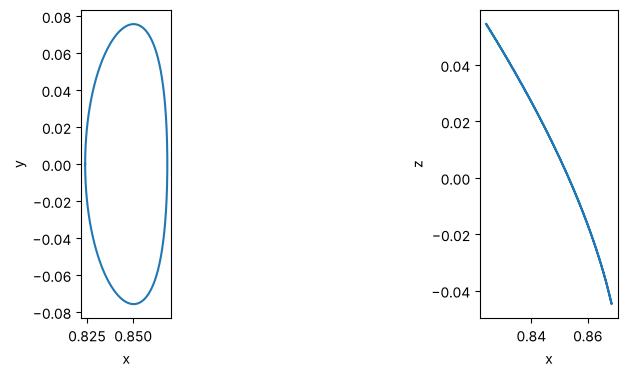

In [3]:
sol = propagate(s0, (0, T), mu=mu, t_eval=np.linspace(0, T, 600))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(sol.y[0], sol.y[1]); ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_aspect('equal')
ax[1].plot(sol.y[0], sol.y[2]); ax[1].set_xlabel('x'); ax[1].set_ylabel('z'); ax[1].set_aspect('equal')
plt.show()

## 2. Halo families by pseudo-arclength continuation

In [4]:
f1 = compute_halo_family(0.005, 0.20, n_orbits=25, lp='L1', ds=0.005)
f2 = compute_halo_family(0.005, 0.20, n_orbits=25, lp='L2', ds=0.005)
for name, f in (('L1', f1), ('L2', f2)):
    print(name, f'{len(f)} members,  C in [{min(m["C"] for m in f):.4f}, {max(m["C"] for m in f):.4f}],',
          f'max periodicity error {max(periodicity_error(m["state0"], m["T"], mu) for m in f):.1e}')

L1 25 members,  C in [3.0099, 3.1861], max periodicity error 4.7e-10


L2 25 members,  C in [3.0274, 3.1640], max periodicity error 9.9e-09


## 3. Energy-matched L1 → L2 patch through the lunar region

Correct an L1 and an L2 halo to the same Jacobi constant, push the Moon-side unstable manifold of the L1 orbit and the Moon-side stable manifold of the L2 orbit to the plane x = 1 − μ, and look for the closest pair.

In [5]:
r = energy_matched_connection(3.13, f1, f2, mu, n_samples=60)
p = r['patch']
print(f"A_z: L1 {r['Az_L1_km']:,.0f} km,  L2 {r['Az_L2_km']:,.0f} km")
print(f"smallest gap {p['min_gap_km']:.0f} km;  best patch: gap {p['gap_km']:.0f} km, dV {p['dv_km_s'] * 1e3:.0f} m/s")

A_z: L1 33,553 km,  L2 35,313 km
smallest gap 351 km;  best patch: gap 351 km, dV 133 m/s


## 4. Earth-approach map (merged from the former `space_highway` repo)

Fate of the interior unstable manifold over 180 days: entry-interface crossing (120 km), lunar impact, escape, or none.

In [6]:
res = earth_approach_map(s0, T, mu, n_samples=24, t_max_days=180)
summarize_map(res)

{'n': 24,
 'entry': 0,
 'moon': 4,
 'escape': 1,
 'none': 19,
 'min_perigee_alt_km': 36361.80528601386,
 'median_perigee_alt_km': 94098.95492391396,
 'in_corridor': 0}